# Classic CNNs: LeNet, AlexNet and VGG (PyTorch)

Following [D2L Ch. 7 CNNs](https://d2l.ai/chapter_convolutional-neural-networks/index.html) and [Ch. 8 Modern CNNs](https://d2l.ai/chapter_convolutional-modern/index.html).

| Model | Year | Key idea |
|-------|------|----------|
| **LeNet-5** | 1998 | conv → pool → conv → pool → dense: the template every CNN still follows |
| **AlexNet** | 2012 | much deeper and wider, ReLU, dropout, trained on GPUs — started the deep learning boom |
| **VGG** | 2014 | build networks from repeated **blocks** of 3×3 convs |

**Contents**
1. Data: Fashion-MNIST
2. A shared training loop
3. LeNet (trained here on CPU)
4. AlexNet (architecture + shape check; training needs a GPU)
5. VGG-11 (architecture + shape check; training needs a GPU)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lee2716/Dive_into_Deep_Learning_Code_Implementation/blob/main/classic_cnns.ipynb)

In [1]:
import time
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


## 1. Data: Fashion-MNIST

70,000 grayscale 28×28 images of clothing in 10 classes — a harder drop-in replacement for MNIST. `resize` lets AlexNet/VGG use larger inputs.

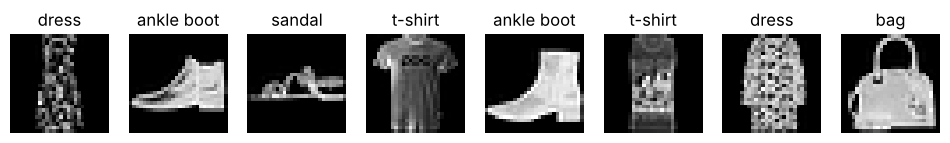

In [2]:
def load_fashion_mnist(batch_size, resize=None):
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    train = datasets.FashionMNIST(root='./data', train=True, transform=trans, download=True)
    test = datasets.FashionMNIST(root='./data', train=False, transform=trans, download=True)
    return (DataLoader(train, batch_size, shuffle=True, num_workers=2),
            DataLoader(test, batch_size, shuffle=False, num_workers=2))

labels_text = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
               'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']

train_iter, test_iter = load_fashion_mnist(256)
X, y = next(iter(train_iter))
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, label in zip(axes, X, y):
    ax.imshow(img[0], cmap='gray')
    ax.set_title(labels_text[label])
    ax.axis('off')
plt.show()

## 2. Training Loop

One loop for every model below: Xavier initialization, minibatch SGD, cross-entropy loss, and test accuracy after each epoch.

In [3]:
def evaluate_accuracy(net, data_iter):
    net.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in data_iter:
            X, y = X.to(device), y.to(device)
            correct += (net(X).argmax(dim=1) == y).sum().item()
            total += y.numel()
    return correct / total


def train(net, train_iter, test_iter, num_epochs, lr):
    def init_weights(m):
        if type(m) in (nn.Linear, nn.Conv2d):
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'test_acc': []}
    start = time.time()
    for epoch in range(num_epochs):
        net.train()
        loss_sum, correct, total = 0.0, 0, 0
        for X, y in train_iter:
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            loss = loss_fn(y_hat, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.numel()
            correct += (y_hat.argmax(dim=1) == y).sum().item()
            total += y.numel()
        history['train_loss'].append(loss_sum / total)
        history['train_acc'].append(correct / total)
        history['test_acc'].append(evaluate_accuracy(net, test_iter))
        print(f"epoch {epoch + 1:2d}: loss {history['train_loss'][-1]:.3f}, "
              f"train acc {history['train_acc'][-1]:.3f}, test acc {history['test_acc'][-1]:.3f}")
    print(f'{total * num_epochs / (time.time() - start):.0f} examples/sec on {device}')
    return history


def plot_history(history, title=''):
    epochs = range(1, len(history['train_loss']) + 1)
    for key in history:
        plt.plot(epochs, history[key], label=key.replace('_', ' '))
    plt.xlabel('epoch')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def layer_shapes(net, X):
    """Print the output shape of every top-level layer."""
    for layer in net:
        X = layer(X)
        print(f'{layer.__class__.__name__:12s} output shape: {tuple(X.shape)}')
    print(f'Total parameters: {sum(p.numel() for p in net.parameters()):,}')

## 3. LeNet-5

Two convolutional blocks (5×5 conv → sigmoid → 2×2 average pooling) extract features; three dense layers classify them.

- `padding=2` on the first conv keeps 28×28 inputs at 28×28 (the original paper used 32×32 images).
- The flattened feature map is 16 channels × 5 × 5 = 400 values.

In [4]:
lenet = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.Sigmoid(),
    nn.Linear(84, 10))

layer_shapes(lenet, torch.rand(1, 1, 28, 28))

Conv2d       output shape: (1, 6, 28, 28)
Sigmoid      output shape: (1, 6, 28, 28)
AvgPool2d    output shape: (1, 6, 14, 14)
Conv2d       output shape: (1, 16, 10, 10)
Sigmoid      output shape: (1, 16, 10, 10)
AvgPool2d    output shape: (1, 16, 5, 5)
Flatten      output shape: (1, 400)
Linear       output shape: (1, 120)
Sigmoid      output shape: (1, 120)
Linear       output shape: (1, 84)
Sigmoid      output shape: (1, 84)
Linear       output shape: (1, 10)
Total parameters: 61,706


Sigmoid networks learn slowly at first, so LeNet needs a large learning rate (0.9).

epoch  1: loss 2.321, train acc 0.102, test acc 0.178


epoch  2: loss 1.594, train acc 0.381, test acc 0.610


epoch  3: loss 0.887, train acc 0.648, test acc 0.603


epoch  4: loss 0.708, train acc 0.723, test acc 0.709


epoch  5: loss 0.641, train acc 0.750, test acc 0.755


epoch  6: loss 0.586, train acc 0.772, test acc 0.778


epoch  7: loss 0.547, train acc 0.788, test acc 0.766


epoch  8: loss 0.513, train acc 0.803, test acc 0.808


epoch  9: loss 0.488, train acc 0.815, test acc 0.816


epoch 10: loss 0.468, train acc 0.823, test acc 0.816
7958 examples/sec on cpu


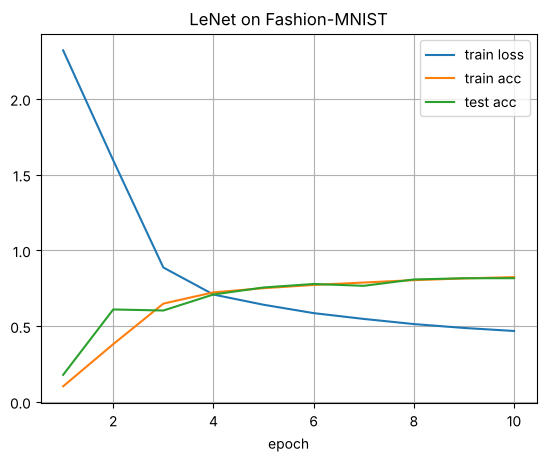

In [5]:
lenet_history = train(lenet, train_iter, test_iter, num_epochs=10, lr=0.9)
plot_history(lenet_history, 'LeNet on Fashion-MNIST')

## 4. AlexNet

Compared with LeNet, AlexNet is:
- **much bigger:** 5 conv layers and two 4096-unit dense layers (~47 M parameters for 10 classes);
- **ReLU** instead of sigmoid — gradients don't vanish, so training is far faster;
- **max pooling** instead of average pooling;
- **dropout** in the dense layers to fight overfitting.

It expects 224×224 inputs, so Fashion-MNIST images are upsampled.

In [6]:
alexnet = nn.Sequential(
    nn.Conv2d(1, 96, kernel_size=11, stride=4, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2),
    nn.Conv2d(96, 256, kernel_size=5, padding=2), nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2),
    nn.Conv2d(256, 384, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(384, 384, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(384, 256, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2),
    nn.Flatten(),
    nn.Linear(6400, 4096), nn.ReLU(), nn.Dropout(p=0.5),
    nn.Linear(4096, 4096), nn.ReLU(), nn.Dropout(p=0.5),
    nn.Linear(4096, 10))

layer_shapes(alexnet, torch.randn(1, 1, 224, 224))

Conv2d       output shape: (1, 96, 54, 54)
ReLU         output shape: (1, 96, 54, 54)
MaxPool2d    output shape: (1, 96, 26, 26)
Conv2d       output shape: (1, 256, 26, 26)
ReLU         output shape: (1, 256, 26, 26)
MaxPool2d    output shape: (1, 256, 12, 12)
Conv2d       output shape: (1, 384, 12, 12)
ReLU         output shape: (1, 384, 12, 12)
Conv2d       output shape: (1, 384, 12, 12)
ReLU         output shape: (1, 384, 12, 12)
Conv2d       output shape: (1, 256, 12, 12)
ReLU         output shape: (1, 256, 12, 12)
MaxPool2d    output shape: (1, 256, 5, 5)
Flatten      output shape: (1, 6400)
Linear       output shape: (1, 4096)
ReLU         output shape: (1, 4096)
Dropout      output shape: (1, 4096)
Linear       output shape: (1, 4096)
ReLU         output shape: (1, 4096)
Dropout      output shape: (1, 4096)
Linear       output shape: (1, 10)
Total parameters: 46,764,746


Training AlexNet at 224×224 takes a few minutes per epoch on a GPU, but hours on a CPU, so this cell only runs when a GPU is available.

In [7]:
if torch.cuda.is_available():
    train_224, test_224 = load_fashion_mnist(128, resize=224)
    alexnet_history = train(alexnet, train_224, test_224, num_epochs=10, lr=0.01)
    plot_history(alexnet_history, 'AlexNet on Fashion-MNIST')
else:
    print('No GPU found: skipping AlexNet training (run in Colab with a GPU runtime).')

No GPU found: skipping AlexNet training (run in Colab with a GPU runtime).


## 5. VGG

VGG's idea: stop designing layers one by one and **repeat a block**:
`n × (3×3 conv, padding 1 → ReLU)` followed by a 2×2 max-pool that halves the resolution.

Two stacked 3×3 convs see a 5×5 region with fewer parameters than one 5×5 conv ($2 \cdot 3^2 = 18$ vs $25$ weights per channel pair) and add an extra non-linearity.

VGG-11 uses 5 blocks with (1, 1, 2, 2, 2) convs: 8 conv layers + 3 dense layers = 11.

In [8]:
def vgg_block(num_convs, in_channels, out_channels):
    layers = []
    for _ in range(num_convs):
        layers += [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1), nn.ReLU()]
        in_channels = out_channels
    layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
    return nn.Sequential(*layers)


def vgg(conv_arch, in_channels=1, num_classes=10):
    blocks = []
    for num_convs, out_channels in conv_arch:
        blocks.append(vgg_block(num_convs, in_channels, out_channels))
        in_channels = out_channels
    return nn.Sequential(
        *blocks, nn.Flatten(),
        nn.Linear(in_channels * 7 * 7, 4096), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(4096, 4096), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(4096, num_classes))


vgg11_arch = ((1, 64), (1, 128), (2, 256), (2, 512), (2, 512))
layer_shapes(vgg(vgg11_arch), torch.randn(1, 1, 224, 224))

Sequential   output shape: (1, 64, 112, 112)
Sequential   output shape: (1, 128, 56, 56)
Sequential   output shape: (1, 256, 28, 28)
Sequential   output shape: (1, 512, 14, 14)
Sequential   output shape: (1, 512, 7, 7)
Flatten      output shape: (1, 25088)
Linear       output shape: (1, 4096)
ReLU         output shape: (1, 4096)
Dropout      output shape: (1, 4096)
Linear       output shape: (1, 4096)
ReLU         output shape: (1, 4096)
Dropout      output shape: (1, 4096)
Linear       output shape: (1, 10)
Total parameters: 128,806,154


Full VGG-11 is heavy (~129 M parameters), so like D2L we train a version with **4× fewer channels** — on a GPU only.

In [9]:
small_arch = [(n, c // 4) for n, c in vgg11_arch]
vgg_small = vgg(small_arch)

if torch.cuda.is_available():
    train_224, test_224 = load_fashion_mnist(128, resize=224)
    vgg_history = train(vgg_small, train_224, test_224, num_epochs=10, lr=0.05)
    plot_history(vgg_history, 'VGG-11 (1/4 width) on Fashion-MNIST')
else:
    print('No GPU found: skipping VGG training (run in Colab with a GPU runtime).')

No GPU found: skipping VGG training (run in Colab with a GPU runtime).


## Exercises

1. Modernize LeNet: replace sigmoid with ReLU and average pooling with max pooling (use `lr=0.1`). How much faster does it learn?
2. AlexNet's first dense layer dominates its parameter count. Compute how many of the ~47 M parameters it holds.
3. Build VGG-16 with `((2, 64), (2, 128), (3, 256), (3, 512), (3, 512))` and compare its parameter count with VGG-11.